**Data Selection**


Dataset Name and Source

For my final project I selected a spinal tumor dataset from the National Cancer Institute’s Surveillance, Epidemiology, and End Results (SEER) Research Data, 1975–2023 (November 2025 Submission). The dataset includes both adult and pediatric patients.

Source URL: https://seer.cancer.gov/data/

Reason for Selection

I chose this dataset because of my work as a neurosurgery resident and my interest in spinal tumors. I have a sincere interest in oncology research and disparities in care and outcomes, so this felt like a good opportunity to explore a topic that is relevant to my career. I also find SEER to be a thorough, well-organized database, which made it a good choice for this project.

Verification of Project Criteria

I confirmed that the dataset meets the project requirements. It includes over 5000 observations and at least 10 predictor variables, and the selected outcome is binary, making it suitable for supervised classification.




In [1]:
import pandas as pd
from google.colab import files
from io import BytesIO

uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(BytesIO(uploaded[filename]))

print("File:", filename)
print("Rows and columns:", df.shape)
display(df.head())
df.info()

Saving SEER_FINAL.csv to SEER_FINAL (1).csv
File: SEER_FINAL (1).csv
Rows and columns: (5831, 25)


,Age recode with <1 year olds and 90+,Sex,Year of diagnosis,Primary Site - labeled,Histologic Type ICD-O-3,Behavior recode for analysis,Grade Recode (thru 2017),ICD-O-3 Hist/behav,Combined Summary Stage with Expanded Regional Codes (2004+),RX Summ--Surg Prim Site (1998-2022),...,Time from diagnosis to treatment in days recode,Median household income inflation adj to 2024,Rural-Urban Continuum Code,Survival months,Survival Days,SEER other cause of death classification,Race and origin (recommended by SEER),Vital status recode (study cutoff used),"Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)","Race recode (W, B, AI, API)"
0,75-79 years,Female,2014,C41.2-Vertebral column,9370,Malignant,Unknown,"9370/3: Chordoma, NOS",Regional by direct extension only,00,...,318,"$120,000+",Counties in metropolitan areas ge 1 million pop,0112,03418,Alive or dead due to cancer,All races/ethnicities,Alive,Non-Hispanic White,White
1,80-84 years,Male,2015,C41.2-Vertebral column,9731,Malignant,B-cell; pre-B; B-precursor,9731/3: Solitary plasmacytoma of bone,Localized only,25,...,032,"$110,000 - $119,999",Counties in metropolitan areas ge 1 million pop,0102,03111,Alive or dead due to cancer,All races/ethnicities,Alive,Non-Hispanic White,White
2,90+ years,Female,2021,C41.2-Vertebral column,9120,Malignant,Blank(s),9120/3: Hemangiosarcoma,Unknown/unstaged/unspecified/DCO,00,...,Unable to calculate,"$120,000+",Counties in metropolitan areas ge 1 million pop,0001,00044,Dead (attributable to causes other than this c...,All races/ethnicities,Dead,Non-Hispanic White,White
3,65-69 years,Female,2014,C41.2-Vertebral column,9220,Malignant,Moderately differentiated; Grade II,"9220/3: Chondrosarcoma, NOS",Localized only,25,...,000,"$110,000 - $119,999",Counties in metropolitan areas ge 1 million pop,0031,00956,Alive or dead due to cancer,All races/ethnicities,Dead,Non-Hispanic White,White
4,55-59 years,Female,2019,C72.0-Spinal cord,9391,Malignant,Blank(s),"9391/3: Ependymoma, NOS",Localized only,22,...,027,"$120,000+",Counties in metropolitan areas ge 1 million pop,0056,01724,Alive or dead due to cancer,All races/ethnicities,Alive,Non-Hispanic White,White


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5831 entries, 0 to 5830
Data columns (total 25 columns):
 #   Column                                                       Non-Null Count  Dtype 
---  ------                                                       --------------  ----- 
 0   Age recode with <1 year olds and 90+                         5831 non-null   object
 1   Sex                                                          5831 non-null   object
 2   Year of diagnosis                                            5831 non-null   int64 
 3   Primary Site - labeled                                       5831 non-null   object
 4   Histologic Type ICD-O-3                                      5831 non-null   int64 
 5   Behavior recode for analysis                                 5831 non-null   object
 6   Grade Recode (thru 2017)                                     5831 non-null   object
 7   ICD-O-3 Hist/behav                                           5831 non-null   object
 8 

In [2]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

target = "Vital status recode (study cutoff used)"
race = "Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)"

print("Vital status categories:")
display(df[target].value_counts(dropna=False))

print("Race and ethnicity categories:")
display(df[race].value_counts(dropna=False))

print("Descriptive statistics:")
display(df.describe(include="all").T)

Vital status categories:


,count
Vital status recode (study cutoff used),
Alive,3789
Dead,2042


Race and ethnicity categories:


,count
"Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",
Non-Hispanic White,3733
Hispanic (All Races),1066
Non-Hispanic Black,535
Non-Hispanic Asian or Pacific Islander,411
Non-Hispanic Unknown Race,46
Non-Hispanic American Indian/Alaska Native,40


Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age recode with <1 year olds and 90+,5831,20,60-64 years,589,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,5831,2,Male,3284,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year of diagnosis,5831.0,NaN,NaN,NaN,2016.43303,4.030493,2010.0,2013.0,2016.0,2020.0,2023.0
Primary Site - labeled,5831,3,C41.2-Vertebral column,3181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Histologic Type ICD-O-3,5831.0,NaN,NaN,NaN,9462.005831,326.251113,8000.0,9391.0,9421.0,9731.0,9930.0
Behavior recode for analysis,5831,3,Malignant,5693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Grade Recode (thru 2017),5831,8,Blank(s),2424,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ICD-O-3 Hist/behav,5831,133,9731/3: Solitary plasmacytoma of bone,1337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Combined Summary Stage with Expanded Regional Codes (2004+),5831,6,Localized only,4174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RX Summ--Surg Prim Site (1998-2022),5831,18,00,2169,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Target and Predictor Variables**

My target variable is vital status at the study cutoff: alive or dead. There are 3,789 records classified as alive and 2,042 classified as dead. Patients have different lengths of follow-up, so I will need to consider that when interpreting the results.

The predictors I am considering include age group, sex, race and ethnicity, year of diagnosis, tumor location, histology, behavior, grade, stage, and treatment information, including surgery, radiation, and chemotherapy. I am also considering time to treatment, county-level median household income, and rurality. These variables are relevant to my interest in racial and ethnic differences in treatment receipt and vital status. Histology is particularly important because different spinal tumors have very different treatment approaches and prognoses.

Before building the model, I will remove columns that are entirely missing or contain the same value for every record and address overlapping variables and changes in surgery coding. I will treat histology codes as categories rather than numerical measurements. I will exclude survival duration and cause-of-death classification from the predictors because they contain information about the outcome I am trying to predict.

In [3]:
# Descriptive statistics for all variables
display(df.describe(include="all").T)

# Counts and percentages for selected categorical variables
columns = [
    "Age recode with <1 year olds and 90+",
    "Sex",
    "Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)",
    "Primary Site - labeled",
    "ICD-O-3 Hist/behav",
    "Reason no cancer-directed surgery",
    "Radiation recode",
    "Chemotherapy recode (yes, no/unk)",
    "Vital status recode (study cutoff used)"
]

for column in columns:
    print(f"\n{column}")

    counts = df[column].value_counts(dropna=False)
    summary = pd.DataFrame({
        "Count": counts,
        "Percent": (counts / len(df) * 100).round(1)
    })

    display(summary)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age recode with <1 year olds and 90+,5831,20,60-64 years,589,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,5831,2,Male,3284,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year of diagnosis,5831.0,NaN,NaN,NaN,2016.43303,4.030493,2010.0,2013.0,2016.0,2020.0,2023.0
Primary Site - labeled,5831,3,C41.2-Vertebral column,3181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Histologic Type ICD-O-3,5831.0,NaN,NaN,NaN,9462.005831,326.251113,8000.0,9391.0,9421.0,9731.0,9930.0
Behavior recode for analysis,5831,3,Malignant,5693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Grade Recode (thru 2017),5831,8,Blank(s),2424,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ICD-O-3 Hist/behav,5831,133,9731/3: Solitary plasmacytoma of bone,1337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Combined Summary Stage with Expanded Regional Codes (2004+),5831,6,Localized only,4174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RX Summ--Surg Prim Site (1998-2022),5831,18,00,2169,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Age recode with <1 year olds and 90+


,Count,Percent
Age recode with <1 year olds and 90+,,
60-64 years,589,10.1
65-69 years,569,9.8
55-59 years,527,9.0
70-74 years,494,8.5
50-54 years,445,7.6
75-79 years,374,6.4
45-49 years,368,6.3
80-84 years,324,5.6
40-44 years,313,5.4



Sex


,Count,Percent
Sex,,
Male,3284,56.3
Female,2547,43.7


...

,Count,Percent
Radiation recode,,
None/Unknown,2840,48.7
Beam radiation,2833,48.6
"Recommended, unknown if administered",91,1.6
Refused (1988+),30,0.5
"Radiation, NOS method or source not specified",23,0.4
Combination of beam with implants or isotopes,12,0.2
Radioactive implants (includes brachytherapy) (1988+),2,0.0



Chemotherapy recode (yes, no/unk)


,Count,Percent
"Chemotherapy recode (yes, no/unk)",,
No/Unknown,4255,73.0
Yes,1576,27.0



Vital status recode (study cutoff used)


,Count,Percent
Vital status recode (study cutoff used),,
Alive,3789,65.0
Dead,2042,35.0


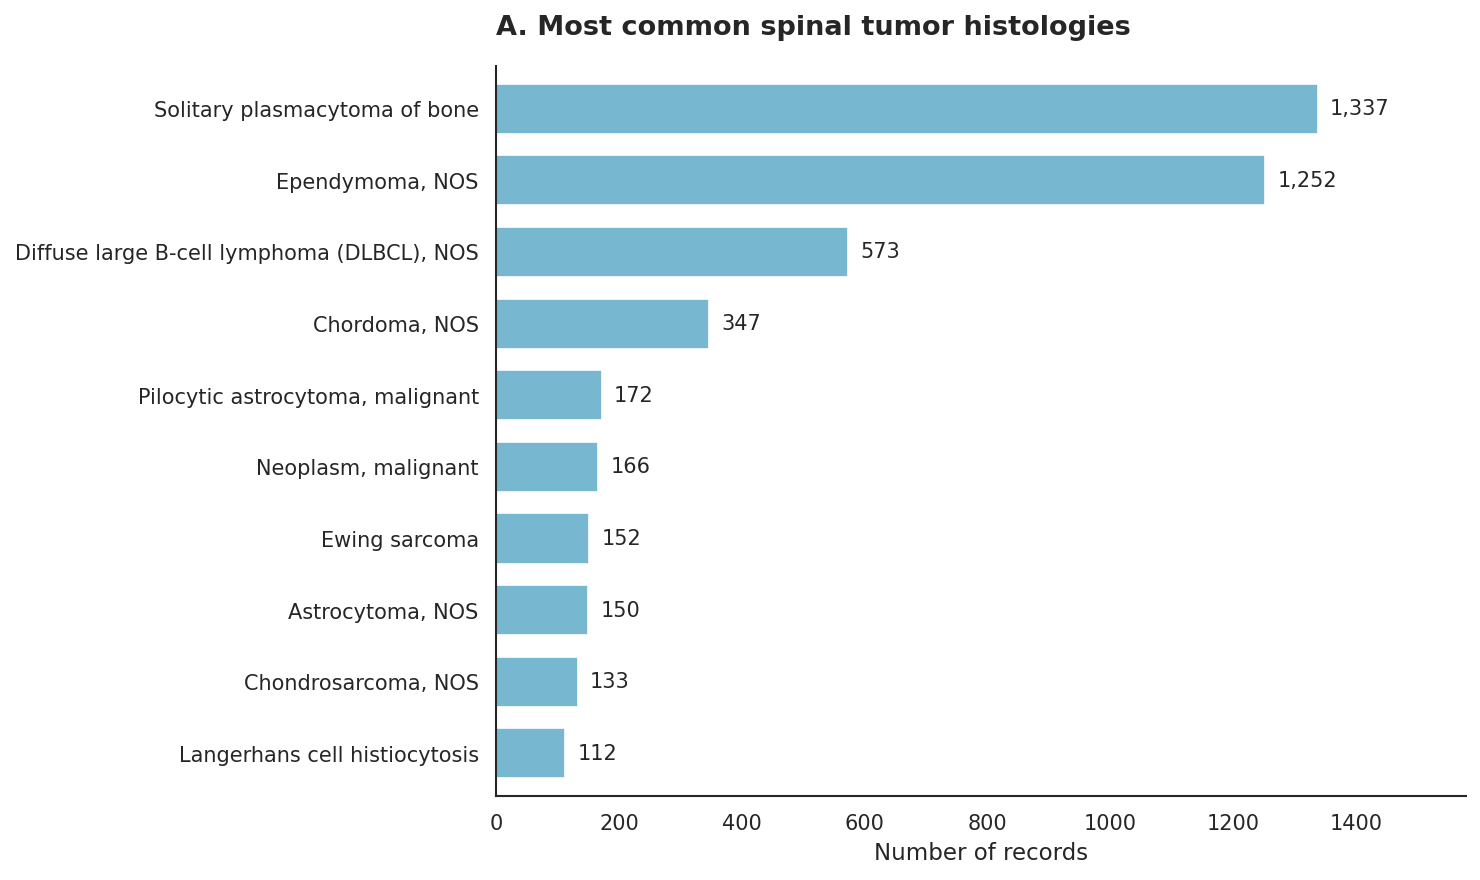

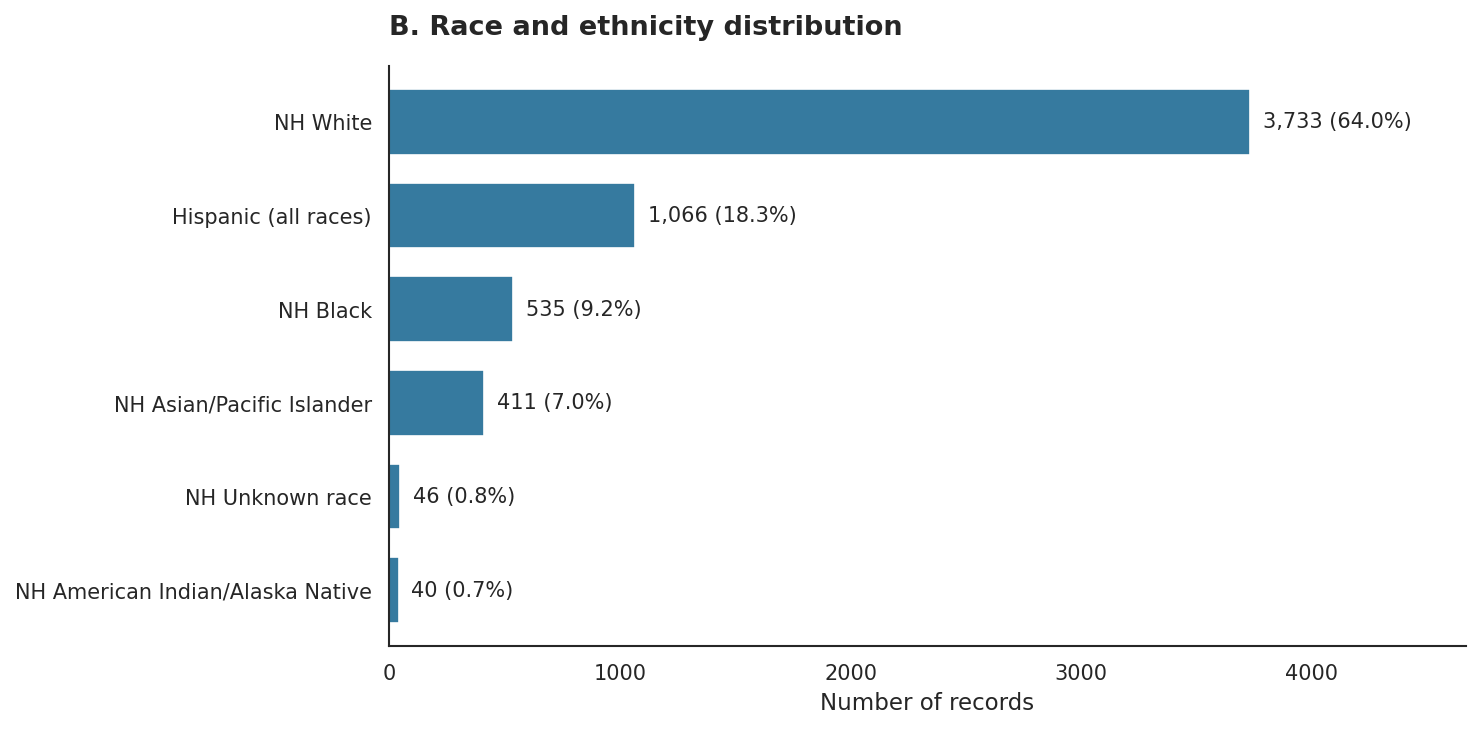

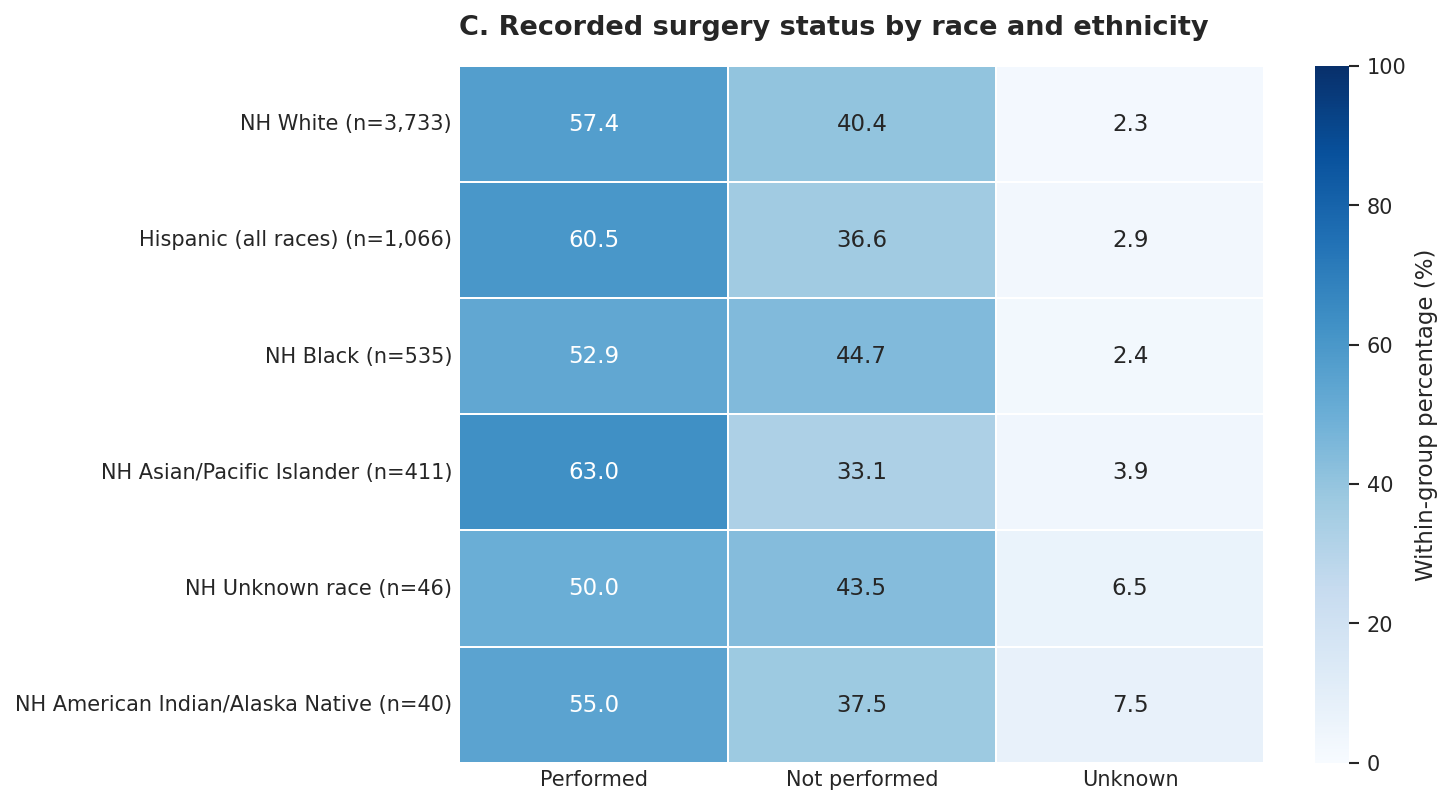

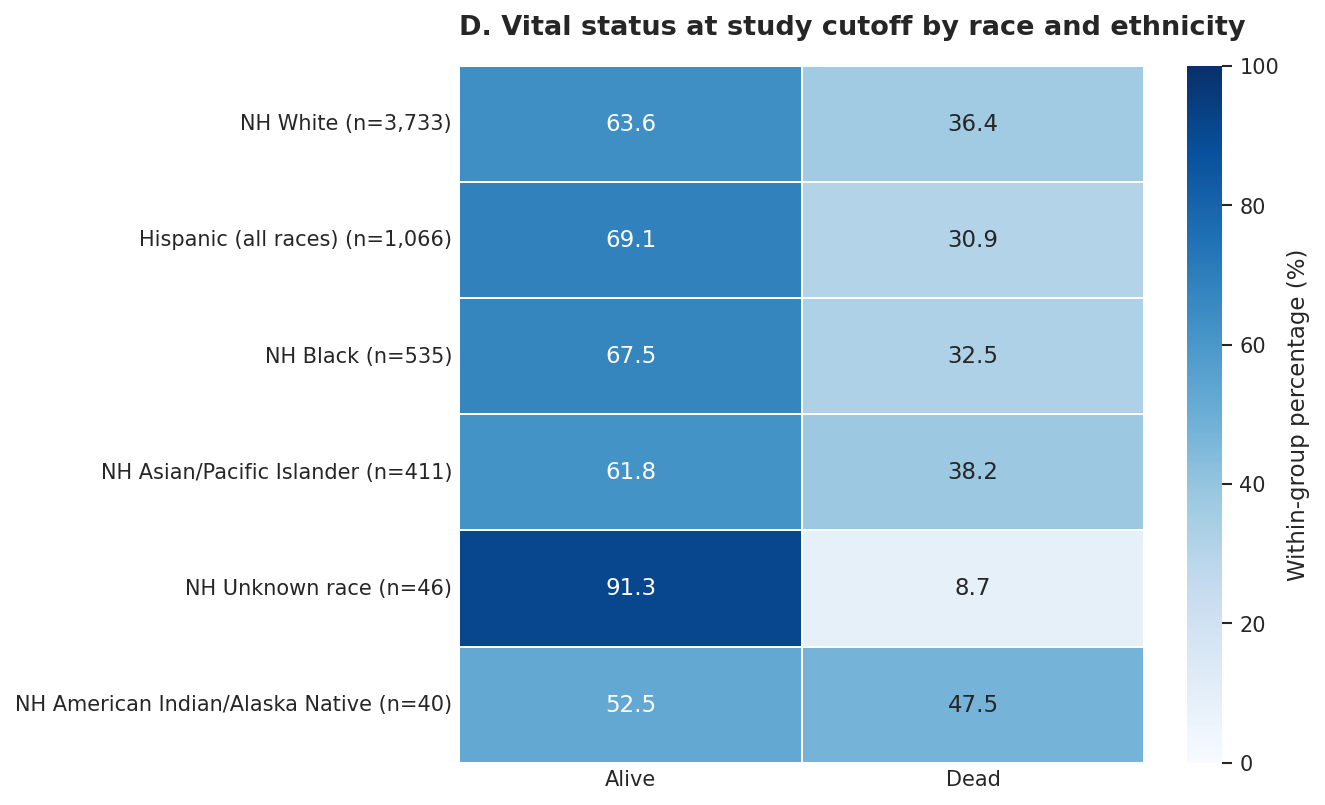

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent figure formatting
sns.set_theme(style="white", context="paper", font_scale=1.2)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

df.columns = df.columns.str.strip()

race = "Race and origin recode (NHW, NHB, NHAIAN, NHAPI, Hispanic)"
histology = "ICD-O-3 Hist/behav"
surgery = "Reason no cancer-directed surgery"
target = "Vital status recode (study cutoff used)"

# Clean labels without changing the original dataset
plot_data = df[[race, histology, surgery, target]].copy()
for column in plot_data.columns:
    plot_data[column] = plot_data[column].astype("string").str.strip()

race_labels = {
    "Non-Hispanic White": "NH White",
    "Non-Hispanic Black": "NH Black",
    "Non-Hispanic Asian or Pacific Islander": "NH Asian/Pacific Islander",
    "Non-Hispanic American Indian/Alaska Native":
        "NH American Indian/Alaska Native",
    "Hispanic (All Races)": "Hispanic (all races)",
    "Non-Hispanic Unknown Race": "NH Unknown race"
}

race_counts = plot_data[race].value_counts()
race_order = race_counts.index

def label_groups(table):
    table = table.reindex(race_order).copy()
    table.index = [
        f"{race_labels.get(group, group)} (n={race_counts[group]:,})"
        for group in table.index
    ]
    return table

def finish_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(f"{filename}.png", dpi=600, bbox_inches="tight")
    fig.savefig(f"{filename}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

# --------------------------------------------------
# Figure 1: Ten most common histologies
# --------------------------------------------------
hist_counts = plot_data[histology].value_counts().head(10)
hist_counts.index = hist_counts.index.str.replace(
    r"^\d+/\d+:\s*", "", regex=True
)
hist_counts = hist_counts.sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
hist_counts.plot.barh(ax=ax, color="#78B7D0", width=0.7)

ax.set_title("A. Most common spinal tumor histologies", loc="left", pad=15)
ax.set_xlabel("Number of records")
ax.set_ylabel("")
ax.set_xlim(0, hist_counts.max() * 1.18)

for position, count in enumerate(hist_counts):
    ax.text(
        count + hist_counts.max() * 0.015,
        position,
        f"{count:,}",
        va="center",
        fontsize=10
    )

sns.despine(ax=ax)
finish_figure(fig, "Figure1_histology")

# --------------------------------------------------
# Figure 2: Race and ethnicity distribution
# --------------------------------------------------
race_plot = race_counts.rename(index=race_labels).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
race_plot.plot.barh(ax=ax, color="#367A9F", width=0.7)

ax.set_title("B. Race and ethnicity distribution", loc="left", pad=15)
ax.set_xlabel("Number of records")
ax.set_ylabel("")
ax.set_xlim(0, race_plot.max() * 1.25)

for position, count in enumerate(race_plot):
    percentage = count / len(plot_data) * 100
    ax.text(
        count + race_plot.max() * 0.015,
        position,
        f"{count:,} ({percentage:.1f}%)",
        va="center",
        fontsize=10
    )

sns.despine(ax=ax)
finish_figure(fig, "Figure2_race_ethnicity")

# --------------------------------------------------
# Classify surgery status
# Unknown status remains separate from nonreceipt
# --------------------------------------------------
s = plot_data[surgery]

unknown_surgery = (
    s.str.contains("unknown", case=False, na=False)
    | s.isin(["Blank(s)", ""])
    | s.isna()
)

surgery_status = pd.Series(
    "Not performed", index=plot_data.index, dtype="string"
)
surgery_status.loc[unknown_surgery] = "Unknown"
surgery_status.loc[
    s.eq("Surgery performed").fillna(False)
] = "Performed"

# --------------------------------------------------
# Figure 3: Surgery status by race and ethnicity
# --------------------------------------------------
surgery_pct = pd.crosstab(
    plot_data[race], surgery_status, normalize="index"
).mul(100)

surgery_pct = label_groups(surgery_pct).reindex(
    columns=["Performed", "Not performed", "Unknown"],
    fill_value=0
)

fig, ax = plt.subplots(figsize=(10, 5.5))

sns.heatmap(
    surgery_pct,
    ax=ax,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    linecolor="white",
    annot_kws={"fontsize": 11},
    cbar_kws={"label": "Within-group percentage (%)"}
)

ax.set_title(
    "C. Recorded surgery status by race and ethnicity",
    loc="left",
    pad=15
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="both", length=0)
plt.setp(ax.get_yticklabels(), rotation=0)

finish_figure(fig, "Figure3_surgery_by_race")

# --------------------------------------------------
# Figure 4: Vital status by race and ethnicity
# --------------------------------------------------
vital_pct = pd.crosstab(
    plot_data[race], plot_data[target], normalize="index"
).mul(100)

vital_pct = label_groups(vital_pct).reindex(
    columns=["Alive", "Dead"], fill_value=0
)

fig, ax = plt.subplots(figsize=(9, 5.5))

sns.heatmap(
    vital_pct,
    ax=ax,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.8,
    linecolor="white",
    annot_kws={"fontsize": 11},
    cbar_kws={"label": "Within-group percentage (%)"}
)

ax.set_title(
    "D. Vital status at study cutoff by race and ethnicity",
    loc="left",
    pad=15
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="both", length=0)
plt.setp(ax.get_yticklabels(), rotation=0)

finish_figure(fig, "Figure4_vital_status_by_race")

In [5]:
# ==================================================
# DATA QUALITY ASSESSMENT
# ==================================================

# Assess missing values and explicitly coded unknown values
quality_rows = []

for column in df.columns:
    values = df[column].astype("string").str.strip()

    coded_unknown = (
        values.str.contains("unknown", case=False, na=False)
        | values.isin(["Blank(s)", "", "Unable to calculate"])
    )

    quality_rows.append({
        "Variable": column,
        "Missing values": int(df[column].isna().sum()),
        "Blank/unknown/unavailable values": int(coded_unknown.sum()),
        "Unique nonmissing values": int(
            values.replace({"Blank(s)": pd.NA, "": pd.NA}).nunique()
        )
    })

quality_summary = pd.DataFrame(quality_rows)

display(quality_summary)

print("Columns with no variation:")
display(
    quality_summary[
        quality_summary["Unique nonmissing values"] <= 1
    ]
)

,Variable,Missing values,Blank/unknown/unavailable values,Unique nonmissing values
0,Age recode with <1 year olds and 90+,0,0,20
1,Sex,0,0,2
2,Year of diagnosis,0,0,14
3,Primary Site - labeled,0,0,3
4,Histologic Type ICD-O-3,0,0,133
5,Behavior recode for analysis,0,0,3
6,Grade Recode (thru 2017),0,3958,7
7,ICD-O-3 Hist/behav,0,0,133
8,Combined Summary Stage with Expanded Regional ...,0,398,6
9,RX Summ--Surg Prim Site (1998-2022),0,410,17


Columns with no variation:


,Variable,Missing values,Blank/unknown/unavailable values,Unique nonmissing values
14,RX Summ--Reg LN Examined (1998-2002),0,5831,0
21,Race and origin (recommended by SEER),0,0,1


**Data Quality Assessment**

While there are no null values in the imported dataset, some information is recorded as “Blank(s),” “Unknown,” or “Unable to calculate.” Grade is blank or unknown in 3,958 records (67.9%), and time to treatment is unavailable in 882 records (15.1%). Race and ethnicity are unknown in 46 records (0.8%). Vital status is available for all 5,831 records.

I identified two columns that did not provide useful information. The regional lymph node variable is entirely blank, and the original race variable lists every record as “All races/ethnicities.” I will remove these columns and use the race and ethnicity variable that includes distinct groups.

The two surgery columns cover different diagnosis years, which explains their complementary pattern of blanks. I will review the coding definitions before combining them. Radiation and chemotherapy also include categories that combine no treatment with unknown treatment status. Because of this, I cannot assume that every patient in these categories did not receive treatment.

Before modeling, I will encode categorical variables, remove overlapping predictors, and determine how to handle unavailable information. I will also exclude survival duration and cause-of-death classification from the predictors because they contain information about the outcome. Differences in histology, follow-up duration, and the size of each racial and ethnic group will also be important when interpreting the results.

**Project Planning**

**Proposed Prediction Problem**

I want to examine whether there are racial and ethnic disparities in treatment receipt and survival status among adult and pediatric patients with spinal tumors. This is closely related to my work as a neurosurgery resident and my interest in oncology and disparities research. I will consider age, histology, tumor location, and stage when comparing groups, since these factors can influence both treatment decisions and outcomes.

For the machine learning component, I plan to build a binary classification model to predict survival status using demographic, tumor, and treatment characteristics. I also want to examine whether racial and ethnic differences in survival status persist after accounting for these characteristics. My goal is to identify patterns that warrant further investigation, while recognizing that these data cannot establish causation.

**Target Variable**

My target variable is survival status at the study cutoff, distinguishing patients who were living at that time from those who had died. These categories will be coded as 0 and 1, respectively. There are 3,789 patients recorded as living and 2,042 who had died. Patients have different lengths of follow-up, so this does not represent survival at a fixed interval after diagnosis.

**Candidate Evaluation Metric**

I plan to use ROC-AUC as the primary measure of how well the model distinguishes between the two survival status groups. I will also examine how often the model correctly classifies patients and the types of errors it makes. Since disparities are my main interest, I will separately compare treatment receipt and adjusted associations with survival status across racial and ethnic groups. These comparisons will address my research question, while the evaluation metrics will assess the model’s predictive performance.